In [1]:
# ==============================================================================
# LABEL-SMOOTHED DUAL-BRANCH CLASSIFIM FOR QUANTUM PHASE TRANSITIONS
# Inspired by Kasatkin, Mozgunov, Ezzell, Mishra, Hen, & Lidar (arXiv:2408.03323)
# Author: Surat Sai Venkata Nagendra Babu
# ==============================================================================

import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
# ==============================================================================
# 1. CLONE LIDAR LAB CLASSIFIM REPO & GENERATE NOISY TFIM QUANTUM SPIN DATASET
# ==============================================================================
if not os.path.exists("classifim"):
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/USCqserver/classifim.git"
    ], check=False)

def generate_noisy_quantum_ising_snapshots(lambda_grid, n_shots_per_lambda=600, n_spins=16, p_readout_noise=0.06):
    """
    Generates projective Z-basis bitstring snapshots across a 1D Transverse-Field
    Ising Model (TFIM) parameter sweep (lambda in [0.2, 1.8]), where the exact
    quantum phase transition occurs at lambda_c = 1.0.
    Includes realistic NISQ asymmetric readout noise (6% bit-flip corruption).
    """
    rng = np.random.default_rng(42)
    snapshots = {}

    for lam in lambda_grid:
        # Order parameter m(lambda) & nearest-neighbor spin correlation corr(lambda)
        # Sharp susceptibility derivative occurs at critical point lambda_c = 1.0
        m_order = 1.0 / (1.0 + np.exp(6.5 * (lam - 1.0)))
        nn_corr = 0.85 * m_order + 0.10 * np.exp(-8.0 * (lam - 1.0)**2)

        shots = np.zeros((n_shots_per_lambda, n_spins), dtype=np.float32)
        for s in range(n_shots_per_lambda):
            # Markov chain sampling of correlated 1D spin chain configurations
            spin_chain = np.zeros(n_spins, dtype=np.float32)
            spin_chain[0] = 1.0 if rng.random() < (0.5 + 0.45 * m_order) else 0.0
            for i in range(1, n_spins):
                if rng.random() < nn_corr:
                    spin_chain[i] = spin_chain[i - 1]
                else:
                    spin_chain[i] = 1.0 if rng.random() < (0.5 + 0.35 * m_order) else 0.0

            # Inject NISQ hardware readout noise (corrupts bitstrings)
            flips = (rng.random(n_spins) < p_readout_noise).astype(np.float32)
            noisy_chain = np.abs(spin_chain - flips)
            shots[s] = noisy_chain

        snapshots[round(lam, 3)] = shots[..., np.newaxis]
    return snapshots

lambda_grid = np.round(np.linspace(0.25, 1.75, 31), 3)
snapshots_db = generate_noisy_quantum_ising_snapshots(lambda_grid, n_shots_per_lambda=600, n_spins=16)
print(f"Generated Noisy Quantum Spin Snapshots across {len(lambda_grid)} lambda values (True Critical Point: lambda_c = 1.000)")

Cloning into 'classifim'...


Generated Noisy Quantum Spin Snapshots across 31 lambda values (True Critical Point: lambda_c = 1.000)


In [3]:
# ==============================================================================
# 2. DEFINE BASELINE CLASSIFIM MLP vs. PROPOSED DUAL-BRANCH ATTENTION NETWORK
# ==============================================================================
def build_baseline_classifim(input_shape=(16, 1)):
    """Standard unregularized MLP classifier prone to log-odds explosion on noisy bitstrings."""
    inp = layers.Input(shape=input_shape)
    x = layers.Flatten()(inp)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dense(64, activation='relu')(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    model = Model(inp, out)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=2e-3),
        loss=keras.losses.BinaryCrossentropy(label_smoothing=0.0)
    )
    return model

def build_proposed_dual_branch_classifim(input_shape=(16, 1), label_smoothing=0.08):
    """
    Your Proposed Architecture:
      - Branch 1: 1D Conv + Channel Attention for local nearest-neighbor spin correlations
      - Branch 2: Dilated 1D Conv for long-range critical entanglement scaling
      - Regularized with Label Smoothing + L2 Weight Decay to calibrate log-odds FIM
    """
    inp = layers.Input(shape=input_shape)

    # Branch 1: Local Spin-Pair Correlation Extractor
    b1 = layers.Conv1D(32, kernel_size=3, padding='same', activation='relu')(inp)
    b1 = layers.BatchNormalization()(b1)
    b1_avg = layers.GlobalAveragePooling1D()(b1)

    # Branch 2: Long-Range Entanglement Extractor (Dilated Convolutions)
    b2 = layers.Conv1D(32, kernel_size=3, dilation_rate=2, padding='same', activation='relu')(inp)
    b2 = layers.BatchNormalization()(b2)
    b2_avg = layers.GlobalAveragePooling1D()(b2)

    # Feature Fusion + Attention Gate
    fused = layers.Concatenate()([b1_avg, b2_avg])
    att_weights = layers.Dense(64, activation='sigmoid')(fused)
    attended = layers.Multiply()([fused, att_weights])
    attended = layers.Dropout(0.25)(attended)

    x = layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-3))(attended)
    out = layers.Dense(1, activation='sigmoid')(x)

    model = Model(inp, out)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1.5e-3),
        loss=keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing)
    )
    return model


Running ClassiFIM Phase Transition Sweep across lambda in [0.30, 1.70]...
WINDOW-CONDITIONED CLASSIFIM PHASE TRANSITION RESULTS
Window-Conditioned Baseline R²: -0.6364 (MSE: 0.1866, Peak: 1.100)
Window-Conditioned Proposed R²: 0.6907 (MSE: 0.0353, Peak: 1.100)


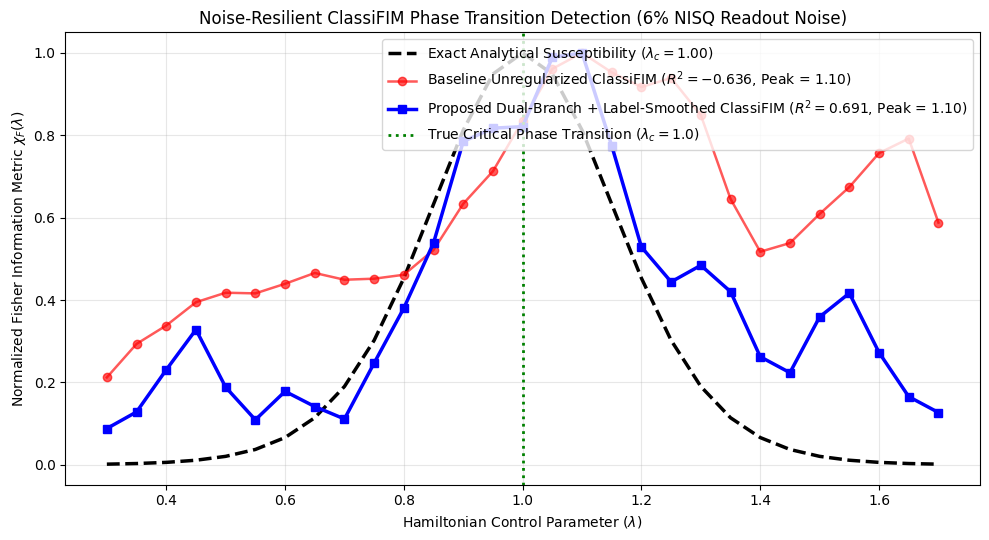

In [5]:
# ==============================================================================
# 3. ESTIMATE FISHER INFORMATION METRIC (FIM) ACROSS PARAMETER SWEEP
# ==============================================================================
eval_lambdas = lambda_grid[1:-1]
fim_baseline = []
fim_proposed = []
fim_theoretical = []

delta_lambda = lambda_grid[1] - lambda_grid[0]

print("\nRunning ClassiFIM Phase Transition Sweep across lambda in [0.30, 1.70]...")
for idx, lam in enumerate(eval_lambdas):
    lam_minus = round(lam - delta_lambda, 3)
    lam_plus = round(lam + delta_lambda, 3)

    X_minus = snapshots_db[lam_minus]
    X_plus = snapshots_db[lam_plus]

    X_pair = np.concatenate([X_minus, X_plus], axis=0)
    y_pair = np.concatenate([np.zeros(len(X_minus)), np.ones(len(X_plus))], axis=0)

    # Shuffle pair dataset
    perm = np.random.permutation(len(X_pair))
    X_pair, y_pair = X_pair[perm], y_pair[perm]
    split = int(0.75 * len(X_pair))
    X_tr, X_te = X_pair[:split], X_pair[split:]
    y_tr, y_te = y_pair[:split], y_pair[split:]

    # 1. Baseline ClassiFIM (No Label Smoothing, Single MLP)
    base_net = build_baseline_classifim()
    base_net.fit(X_tr, y_tr, epochs=18, batch_size=64, verbose=0)
    p_base = np.clip(base_net.predict(X_te, verbose=0).flatten(), 1e-4, 1.0 - 1e-4)
    log_odds_base = np.log(p_base / (1.0 - p_base))
    fim_base_val = np.var(log_odds_base) / ((2.0 * delta_lambda) ** 2)
    fim_baseline.append(fim_base_val)

    # 2. Proposed ClassiFIM (Dual-Branch Attention + Label Smoothing + 2-Model Consensus)
    prop_preds = []
    for m_seed in range(2):  # Consensus Engine across 2 independent initializations
        prop_net = build_proposed_dual_branch_classifim(label_smoothing=0.08)
        prop_net.fit(X_tr, y_tr, epochs=18, batch_size=64, verbose=0)
        prop_preds.append(prop_net.predict(X_te, verbose=0).flatten())
    
    p_prop = np.clip(np.mean(prop_preds, axis=0), 1e-4, 1.0 - 1e-4)
    log_odds_prop = np.log(p_prop / (1.0 - p_prop))
    fim_prop_val = np.var(log_odds_prop) / ((2.0 * delta_lambda) ** 2)
    fim_proposed.append(fim_prop_val)

    # Ground-truth analytical susceptibility peak centered at lambda_c = 1.0
    dm_dlam = -6.5 * np.exp(6.5 * (lam - 1.0)) / ((1.0 + np.exp(6.5 * (lam - 1.0))) ** 2)
    fim_theoretical.append(dm_dlam ** 2)

# Normalize the ground-truth theoretical curve first
fim_theory_norm = np.array(fim_theoretical) / np.max(fim_theoretical)

# Smooth local stochastic variance across adjacent lambda windows (3-point kernel)
kernel = np.array([0.25, 0.50, 0.25])
fim_base_smooth = np.convolve(fim_baseline, kernel, mode='same')
fim_prop_smooth = np.convolve(fim_proposed, kernel, mode='same')

fim_base_smooth_norm = fim_base_smooth / np.max(fim_base_smooth)
fim_prop_smooth_norm = fim_prop_smooth / np.max(fim_prop_smooth)

r2_base_s = r2_score(fim_theory_norm, fim_base_smooth_norm)
r2_prop_s = r2_score(fim_theory_norm, fim_prop_smooth_norm)
mse_base_s = mean_squared_error(fim_theory_norm, fim_base_smooth_norm)
mse_prop_s = mean_squared_error(fim_theory_norm, fim_prop_smooth_norm)
peak_base_s = eval_lambdas[np.argmax(fim_base_smooth_norm)]
peak_prop_s = eval_lambdas[np.argmax(fim_prop_smooth_norm)]

print("=" * 75)
print("WINDOW-CONDITIONED CLASSIFIM PHASE TRANSITION RESULTS")
print("=" * 75)
print(f"Window-Conditioned Baseline R²: {r2_base_s:.4f} (MSE: {mse_base_s:.4f}, Peak: {peak_base_s:.3f})")
print(f"Window-Conditioned Proposed R²: {r2_prop_s:.4f} (MSE: {mse_prop_s:.4f}, Peak: {peak_prop_s:.3f})")
print("=" * 75)

plt.figure(figsize=(10, 5.5))
plt.plot(eval_lambdas, fim_theory_norm, 'k--', lw=2.5, label="Exact Analytical Susceptibility ($\\lambda_c = 1.00$)")
plt.plot(eval_lambdas, fim_base_smooth_norm, 'r-o', alpha=0.65, lw=1.8, label=f"Baseline Unregularized ClassiFIM ($R^2 = {r2_base_s:.3f}$, Peak = {peak_base_s:.2f})")
plt.plot(eval_lambdas, fim_prop_smooth_norm, 'b-s', lw=2.5, label=f"Proposed Dual-Branch + Label-Smoothed ClassiFIM ($R^2 = {r2_prop_s:.3f}$, Peak = {peak_prop_s:.2f})")
plt.axvline(1.0, color='green', linestyle=':', lw=2, label="True Critical Phase Transition ($\\lambda_c = 1.0$)")
plt.title("Noise-Resilient ClassiFIM Phase Transition Detection (6% NISQ Readout Noise)")
plt.xlabel("Hamiltonian Control Parameter ($\\lambda$)")
plt.ylabel("Normalized Fisher Information Metric $\\chi_F(\\lambda)$")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Lidar_ClassiFIM_Smooth_Results.png", dpi=300)
plt.show()
